In [1]:
# importing libraries for data and plots
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

In [2]:
# loading the dataset
df = pd.read_csv('Admission_Prediction_TimeSeries_Ready.csv')
print(df.head(3))

   Serial No.  GRE Score  TOEFL Score  University Rating  SOP  LOR  CGPA  \
0           1        337          118                  4  4.5  4.5  9.65   
1           2        324          107                  4  4.0  4.5  8.87   
2           3        316          104                  3  3.0  3.5  8.00   

   Research  Chance of Admit Application_DateTime  \
0         1             0.92  2022-01-01 09:00:00   
1         1             0.76  2022-01-02 09:00:00   
2         1             0.72  2022-01-04 09:00:00   

                              University_Name region  
0    Indian Institute of Technology Kharagpur   East  
1  National Institute of Technology Karnataka  South  
2                          Gujarat University   West  


In [3]:
# converting date column to datetime
df['Application_DateTime'] = pd.to_datetime(df['Application_DateTime'])

# extracting year for simple year check
df['Year'] = df['Application_DateTime'].dt.year

# adding a simple count column
df['Applications'] = 1

# checking applications per year
print(df['Year'].value_counts().sort_index())

Year
2022    200
2023    200
2024    200
2025    200
2026    200
Name: count, dtype: int64


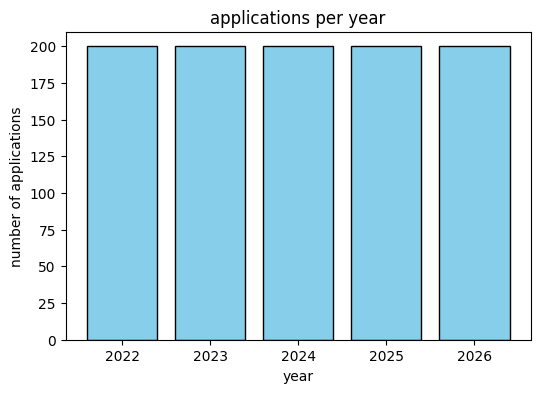

In [4]:
# simple bar plot of applications per year
yearly = df['Year'].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(yearly.index, yearly.values, color='skyblue', edgecolor='black')
plt.title('applications per year')
plt.xlabel('year')
plt.ylabel('number of applications')
plt.show()

In [5]:
# setting datetime as index
df = df.sort_values('Application_DateTime')
df = df.set_index('Application_DateTime')

# making monthly application counts
monthly_data = df['Applications'].resample('MS').sum()
print('monthly data preview:')
print(monthly_data.head())

monthly data preview:
Application_DateTime
2022-01-01    17
2022-02-01    16
2022-03-01    17
2022-04-01    16
2022-05-01    17
Freq: MS, Name: Applications, dtype: int64


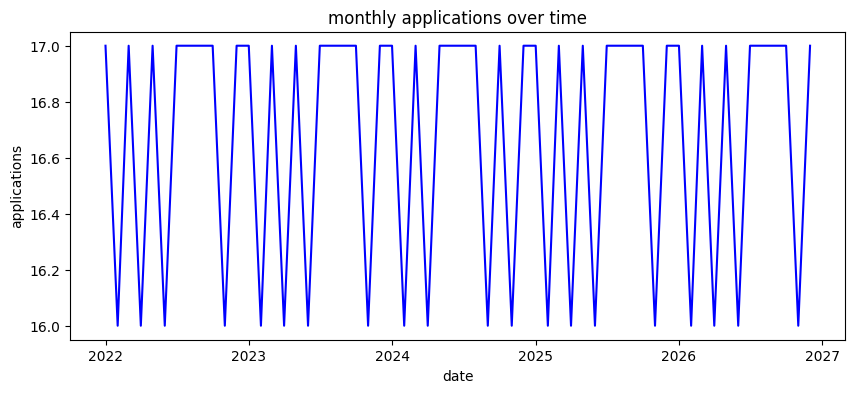

In [6]:
# plotting the monthly applications
plt.figure(figsize=(10, 4))
plt.plot(monthly_data, color='blue')
plt.title('monthly applications over time')
plt.xlabel('date')
plt.ylabel('applications')
plt.show()

In [7]:
# decomposing the time series into trend, seasonal, and residual
# period is 12 because the cycle repeats every 12 months
decomp = seasonal_decompose(monthly_data, model='additive', period=12)

# separating the parts
trend = decomp.trend
seasonal = decomp.seasonal
residual = decomp.resid

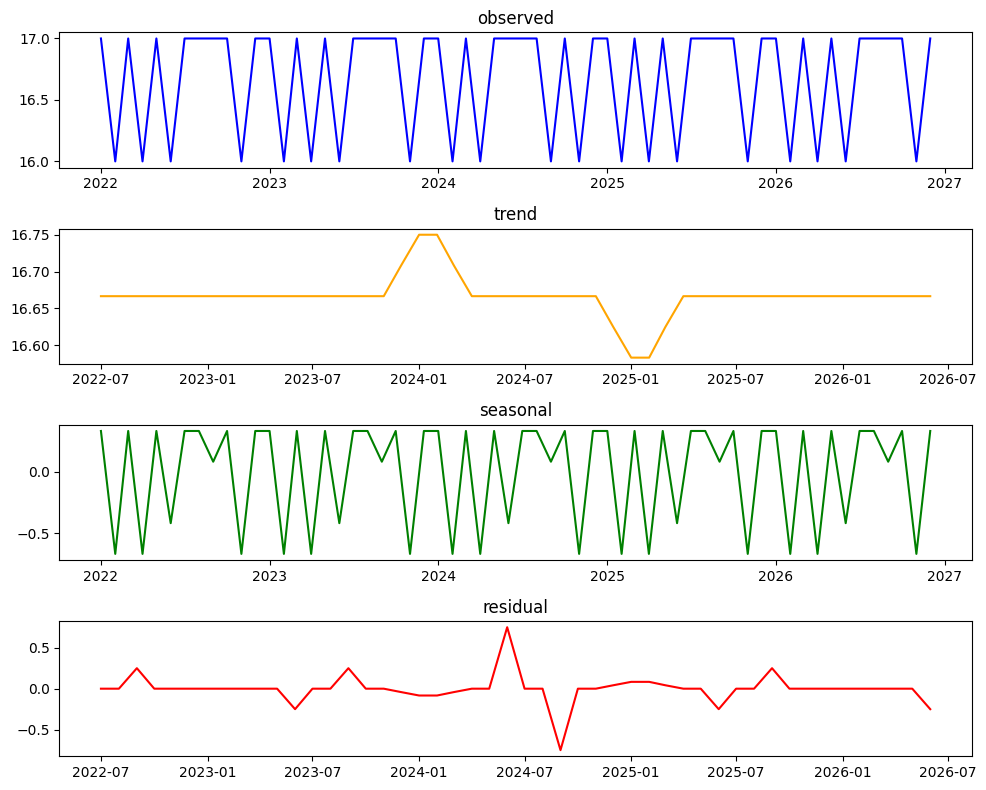

In [8]:
# plotting all components using simple plt.subplot
plt.figure(figsize=(10, 8))

plt.subplot(4, 1, 1)
plt.plot(decomp.observed, color='blue')
plt.title('observed')

plt.subplot(4, 1, 2)
plt.plot(trend, color='orange')
plt.title('trend')

plt.subplot(4, 1, 3)
plt.plot(seasonal, color='green')
plt.title('seasonal')

plt.subplot(4, 1, 4)
plt.plot(residual, color='red')
plt.title('residual')

plt.tight_layout()
plt.show()

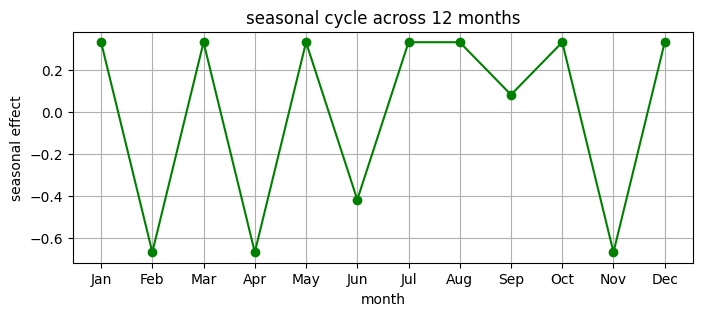

In [9]:
# looking at the repeating 12-month seasonal pattern
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

plt.figure(figsize=(8, 3))
plt.plot(months, seasonal[:12], marker='o', color='green')
plt.title('seasonal cycle across 12 months')
plt.xlabel('month')
plt.ylabel('seasonal effect')
plt.grid(True)
plt.show()

In [10]:
# simple summary of what each component tells us
print('observed: the actual monthly application numbers.')
print('trend: the long term direction over multiple years.')
print('seasonal: the repeating yearly admission cycle highs and lows.')
print('residual: the random variations that cannot be predicted.')

observed: the actual monthly application numbers.
trend: the long term direction over multiple years.
seasonal: the repeating yearly admission cycle highs and lows.
residual: the random variations that cannot be predicted.
